# Copiar al ribosoma: péptidos de la cabeza a la cola, sin proteger nada

**El ribosoma ensambla péptidos sin proteger un solo aminoácido**, y lo hace de la cabeza a la cola (N → C). La química de laboratorio lleva décadas haciéndolo al revés, de la cola a la cabeza, y con grupos protectores que hay que poner y quitar en cada paso. Un equipo acaba de montar la versión continua del camino del ribosoma: aminoácidos sin proteger, sin aislar nada entre acoplamientos. ¿Qué hizo falta para que funcionara?

**Paper:** Yin et al. (2026). *Continuous N-to-C Peptide Synthesis*. **Nature**.
**DOI:** [10.1038/s41586-026-11448-w](https://doi.org/10.1038/s41586-026-11448-w)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ciencia-a-Mordiscos/lab/blob/main/papers/2026-11-23-sintesis-continua-peptidos-n-a-c/notebook.ipynb)

**Video:** Pendiente

## El enemigo tiene nombre: oxazolona

Ir de la cabeza a la cola con el extremo ácido libre tiene un precio. Al activar ese ácido, la cadena puede cerrarse sobre sí misma y formar un anillo de cinco átomos —una **oxazolona**— que después se vuelve a abrir habiendo perdido la orientación del carbono central. Esa pérdida tiene nombre propio en química de péptidos: **epimerización**. El fármaco con el aminoácido girado al revés no sirve.

Así que el problema no es enganchar aminoácidos: es enganchar 7 seguidos sin que la cadena se retuerza en el camino. El paper reporta ≥95 % de rendimiento medio por acoplamiento y ≤1,0 % de epimerización en 7 acoplamientos consecutivos, con ~10 veces menos aislamientos y hasta ~100 veces menos residuos que la ruta convencional.

Lo que exploramos aquí es la cocina que hay detrás: las tablas de cribado del material suplementario, donde el equipo probó reactivos, aditivos, dosis, tiempos y agua sobre **un mismo modelo de reacción** (un dipéptido más un aminoácido). Son 96 ensayos de aditivos y cinco tablas más.

Un aviso de unidades antes de empezar: todo lo que midieron en esas tablas es **% de área por HPLC a 210 nm** (en la jerga, LCAP) — pureza relativa dentro de la mezcla de reacción, no rendimiento aislado. Los 73,0 % y 71 % de la síntesis final sí son rendimientos. No son la misma cosa y no van en el mismo eje.

In [1]:
# ══════════════════════════════════════════════════════════════
# Configuración — modifica estos valores para explorar
# ══════════════════════════════════════════════════════════════
BLOQUE = 'DMAc:MeCN (1:1)'      # condición del método final; el bloque 'DMAc' es el control de solvente
ADITIVO_CLAVE = '2,6-lutidine'  # el aditivo que el paper se lleva al método
AGUA_MAX = 15.0                 # equivalentes de agua del ensayo de tolerancia
COLOR_DATOS = '#2563EB'
COLOR_ALERTA = '#DC2626'
COLOR_REFERENCIA = '#D97706'
COLOR_SEC = '#059669'
COLOR_VIOLETA = '#7C3AED'
COLOR_GRIS = '#BBBBBB'
FUENTE = 'Fuente: Yin et al. (2026), Nature | Datos: Supplementary Tables 1, 2, 4, 5, 7 y 10 (MOESM1 del mismo DOI)'

import os, re, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats

BASE = 'https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/papers/2026-11-23-sintesis-continua-peptidos-n-a-c'
ARCHIVOS = ['aditivos_screening.csv', 'reagentes_activacion.csv', 'lutidina_dosis.csv',
            'lutidina_momento.csv', 'cinetica_activacion.csv', 'agua_tolerancia.csv']
os.makedirs('datos', exist_ok=True)
os.makedirs('figuras', exist_ok=True)
for a in ARCHIVOS:
    if not os.path.exists(f'datos/{a}'):
        urllib.request.urlretrieve(f'{BASE}/datos/{a}', f'datos/{a}')

style_file = '../../cam.mplstyle'
if not os.path.exists(style_file):
    style_file = '/tmp/cam.mplstyle'
    if not os.path.exists(style_file):
        urllib.request.urlretrieve('https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/cam.mplstyle', style_file)
plt.style.use(style_file)

# Números en formato español: coma decimal, punto de miles ({n:_}), signo menos tipográfico
def es(x):
    s = str(x)
    s = re.sub(r'(?<=\d)\.(?=\d)', ',', s)
    s = re.sub(r'(\d)e\+?(-?)0*(\d+)', r'\1×10^\2\3', s)
    s = re.sub(r'(?<![\w,])-(?=\d)', '−', s)
    return s.replace('_', '.')

def pr(*a):
    print(*[es(x) for x in a])

COMA = FuncFormatter(lambda v, _: es(f'{v:g}'))

# ── Carga ──
ad = pd.read_csv('datos/aditivos_screening.csv')      # Suppl. Table 2: 48 entradas x 2 solventes
rg = pd.read_csv('datos/reagentes_activacion.csv')    # Suppl. Table 1: 8 reactivos de activación
ld = pd.read_csv('datos/lutidina_dosis.csv')          # Suppl. Table 5: dosis-respuesta de lutidina
lm = pd.read_csv('datos/lutidina_momento.csv')        # Suppl. Table 4: momento de adición
ci = pd.read_csv('datos/cinetica_activacion.csv')     # Suppl. Table 7: cinética de activación
ag = pd.read_csv('datos/agua_tolerancia.csv')         # Suppl. Table 10: tolerancia al agua

mix = ad[ad.solvente == BLOQUE].copy()
ctrl = mix[mix.aditivo == '-'].iloc[0]
lut = mix[mix.aditivo == ADITIVO_CLAVE].iloc[0]
adds = mix[mix.aditivo != '-'].copy()

# Las familias químicas son una clasificación NUESTRA (el paper lista los aditivos sin agrupar):
# juntamos las 7 etiquetas del CSV en 3 grupos para poder comparar distribuciones.
SALES = ('triflato metalico', 'haluro metalico', 'sal de paladio')
def grupo(f):
    if 'piridina' in f:
        return 'Piridinas sustituidas'
    if f in SALES:
        return 'Sales metálicas'
    return 'Otros'
adds['grupo'] = adds.familia.map(grupo)

NOMBRES_ES = {'pyridine': 'piridina', '2,6-lutidine': '2,6-lutidina',
              '4-methylpyridine': '4-metilpiridina', '2-methylpyridine': '2-metilpiridina',
              '2,4,6-collidine': '2,4,6-colidina'}

pr(f'{len(ad)} ensayos de aditivos = {ad.entry.nunique()} entradas x {ad.solvente.nunique()} solventes')
pr(f'Bloque del método ({BLOQUE}) — unidad: % de área HPLC a 210 nm (LCAP), 16 h')
pr(f'  Sin aditivo:      producto 5 = {ctrl.producto5_pct} % | oxazolona total = {ctrl.oxazolona_total_pct} % | epi-5 = {ctrl.epi5_pct} %')
pr(f'  Con {NOMBRES_ES[ADITIVO_CLAVE]}: producto 5 = {lut.producto5_pct} % | oxazolona total = {lut.oxazolona_total_pct} % | epi-5 = {lut.epi5_pct} %')
pr(f'  Diferencia: {lut.producto5_pct - ctrl.producto5_pct:+.1f} puntos de producto | oxazolona {ctrl.oxazolona_total_pct / lut.oxazolona_total_pct:.2f} veces menor')
pr(f'Superan al control: {(adds.producto5_pct > ctrl.producto5_pct).sum()} de {len(adds)} | lo empeoran: {(adds.producto5_pct < ctrl.producto5_pct).sum()}')
for g, sub in adds.groupby('grupo'):
    q1, q3 = np.percentile(sub.producto5_pct, [25, 75])
    pr(f'  {g} (n={len(sub)}): mediana {sub.producto5_pct.median():.1f} % | IQR {q1:.1f}-{q3:.1f} %')

96 ensayos de aditivos = 48 entradas x 2 solventes
Bloque del método (DMAc:MeCN (1:1)) — unidad: % de área HPLC a 210 nm (LCAP), 16 h
  Sin aditivo:      producto 5 = 79,8 % | oxazolona total = 14,3 % | epi-5 = 2,2 %
  Con 2,6-lutidina: producto 5 = 94,1 % | oxazolona total = 4,3 % | epi-5 = 0,6 %
  Diferencia: +14,3 puntos de producto | oxazolona 3,33 veces menor
Superan al control: 13 de 47 | lo empeoran: 34
  Otros (n=7): mediana 53,7 % | IQR 37,8-79,3 %
  Piridinas sustituidas (n=5): mediana 91,8 % | IQR 91,3-94,1 %
  Sales metálicas (n=35): mediana 61,6 % | IQR 34,6-78,7 %


Aquí está.

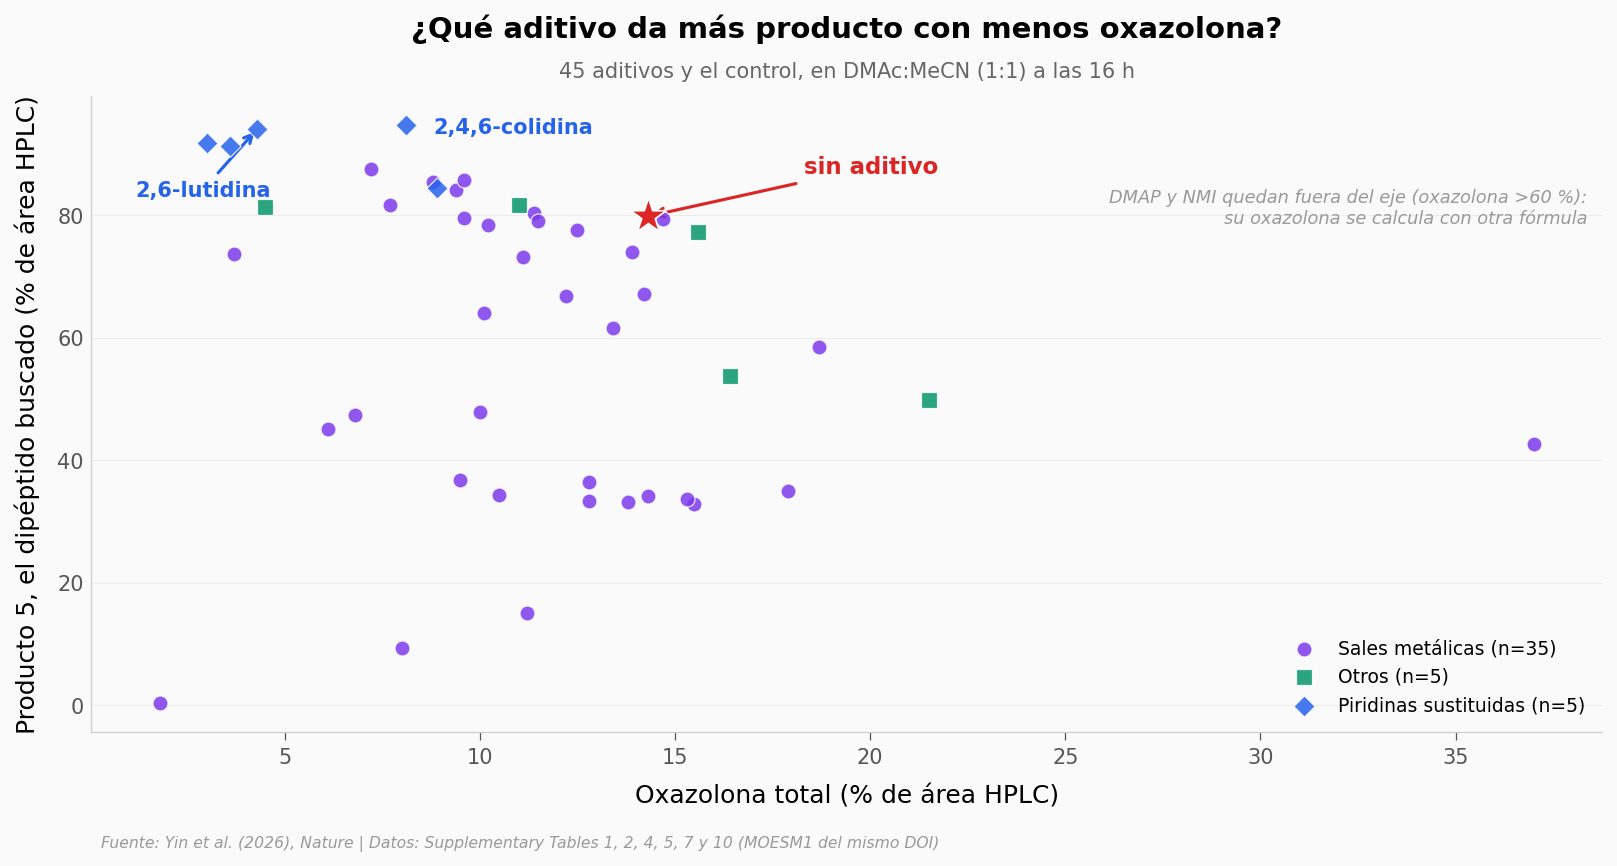

Máximo de producto 5 del cribado: 2,4,6-colidina con 94,7 % (oxazolona 8,1 %)
2,6-lutidina: 94,1 % de producto con oxazolona 4,3 % y epi-5 0,6 %
Piridinas (n=5) vs sales metálicas (n=35): Mann-Whitney U p = 2,1×10^−5 | Cohen d = 1,53


In [2]:
# Hero: cada aditivo del cribado, producto contra oxazolona. La esquina de arriba a la izquierda es la buena.
# Las entradas 47 y 48 (DMAP y NMI) quedan fuera: su oxazolona se calcula con otra fórmula (incluye epi-3).
EXCLUIDAS = [47, 48]
vis = adds[~adds.entry.isin(EXCLUIDAS)]
fuera = adds[adds.entry.isin(EXCLUIDAS)]

fig, ax = plt.subplots(figsize=(13, 5.5))
ESTILO = {'Sales metálicas': (COLOR_VIOLETA, 'o'), 'Otros': (COLOR_SEC, 's'),
          'Piridinas sustituidas': (COLOR_DATOS, 'D')}
for g in ['Sales metálicas', 'Otros', 'Piridinas sustituidas']:
    sub = vis[vis.grupo == g]
    color, marker = ESTILO[g]
    ax.scatter(sub.oxazolona_total_pct, sub.producto5_pct, color=color, marker=marker,
               s=52, alpha=0.85, edgecolors='white', linewidths=0.6, zorder=5, label=f'{g} (n={len(sub)})')

ax.scatter([ctrl.oxazolona_total_pct], [ctrl.producto5_pct], color=COLOR_ALERTA, marker='*',
           s=320, edgecolors='white', linewidths=0.8, zorder=6)
ax.annotate('sin aditivo', xy=(ctrl.oxazolona_total_pct, ctrl.producto5_pct),
            xytext=(ctrl.oxazolona_total_pct + 4.0, ctrl.producto5_pct + 7),
            fontsize=11, fontweight='bold', color=COLOR_ALERTA, ha='left',
            arrowprops=dict(arrowstyle='->', color=COLOR_ALERTA, lw=1.5))

# Solo las dos piridinas que decide el método: etiquetar las cinco amontona el texto
col = vis[vis.aditivo == '2,4,6-collidine'].iloc[0]
ax.annotate(NOMBRES_ES[ADITIVO_CLAVE], xy=(lut.oxazolona_total_pct, lut.producto5_pct),
            xytext=(lut.oxazolona_total_pct - 1.4, lut.producto5_pct - 11),
            fontsize=10, color=COLOR_DATOS, fontweight='bold', ha='center',
            arrowprops=dict(arrowstyle='->', color=COLOR_DATOS, lw=1.5))
ax.text(col.oxazolona_total_pct + 0.7, col.producto5_pct - 0.4, NOMBRES_ES['2,4,6-collidine'],
        fontsize=10, color=COLOR_DATOS, fontweight='bold', ha='left', va='center', zorder=7)

ax.set_xlabel('Oxazolona total (% de área HPLC)')
ax.set_ylabel('Producto 5, el dipéptido buscado (% de área HPLC)')
ax.set_title('¿Qué aditivo da más producto con menos oxazolona?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, es(f'{len(vis)} aditivos y el control, en {BLOQUE} a las 16 h'),
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
ax.text(0.99, 0.80, es(f'DMAP y NMI quedan fuera del eje (oxazolona >60 %):\nsu oxazolona se calcula con otra fórmula'),
        transform=ax.transAxes, fontsize=8.5, color='#999999', ha='right', style='italic')
ax.xaxis.set_major_formatter(COMA)
ax.yaxis.set_major_formatter(COMA)
ax.legend(fontsize=9, loc='lower right', framealpha=0.9)
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/hero_aditivos.png', dpi=200, bbox_inches='tight')
plt.show()

top = vis.loc[vis.producto5_pct.idxmax()]
pr(f'Máximo de producto 5 del cribado: {NOMBRES_ES[top.aditivo]} con {top.producto5_pct} % (oxazolona {top.oxazolona_total_pct} %)')
pr(f'{NOMBRES_ES[ADITIVO_CLAVE]}: {lut.producto5_pct} % de producto con oxazolona {lut.oxazolona_total_pct} % y epi-5 {lut.epi5_pct} %')
pir = adds[adds.grupo == 'Piridinas sustituidas'].producto5_pct
sal = adds[adds.grupo == 'Sales metálicas'].producto5_pct
u = stats.mannwhitneyu(pir, sal, alternative='two-sided')
s_pool = np.sqrt(((len(pir) - 1) * pir.var(ddof=1) + (len(sal) - 1) * sal.var(ddof=1)) / (len(pir) + len(sal) - 2))
pr(f'Piridinas (n={len(pir)}) vs sales metálicas (n={len(sal)}): Mann-Whitney U p = {u.pvalue:.2g} | Cohen d = {(pir.mean() - sal.mean()) / s_pool:.2f}')

Cuatro de las cinco piridinas se amontonan arriba a la izquierda: mediana de 91,8 % de producto con una IQR estrecha (91,3–94,1 %), aunque el rango completo llega hasta 84,5 % (la 2-metilpiridina, con 8,9 % de oxazolona). Las 35 sales metálicas se desparraman por todo el gráfico, con mediana de 61,6 % y una IQR de 34,6 a 78,7 % — algunas ni siquiera dejan reaccionar al dipéptido. La separación entre los dos grupos es grande (Mann-Whitney p = 2,1×10⁻⁵, Cohen's d = 1,53), con el aviso de que las piridinas son solo 5 y el agrupamiento por familia es nuestro, no del paper.

El control sin aditivo aparece donde duele: 79,8 % de producto y 14,3 % de oxazolona. La 2,6-lutidina lo mueve a 94,1 % de producto con 4,3 % de oxazolona — 14,3 puntos más de producto y 3,33 veces menos oxazolona, con el epímero cayendo de 2,2 % a 0,6 %.

Y una trampa de los rankings: el máximo de producto de todo el cribado no es la lutidina, es la 2,4,6-colidina con 94,7 %. Pero su oxazolona total casi dobla a la de la lutidina (8,1 % frente a 4,3 %), y lo que el método necesita es justamente eso: menos oxazolona, menos epímero. Por eso el paper se queda con la lutidina, no con la que gana en el eje vertical.

## ¿Cuánta lutidina, y cuándo?

Un aditivo que funciona plantea dos preguntas de cocina: cuánto hace falta, y si da igual echarlo al principio o a mitad de camino.

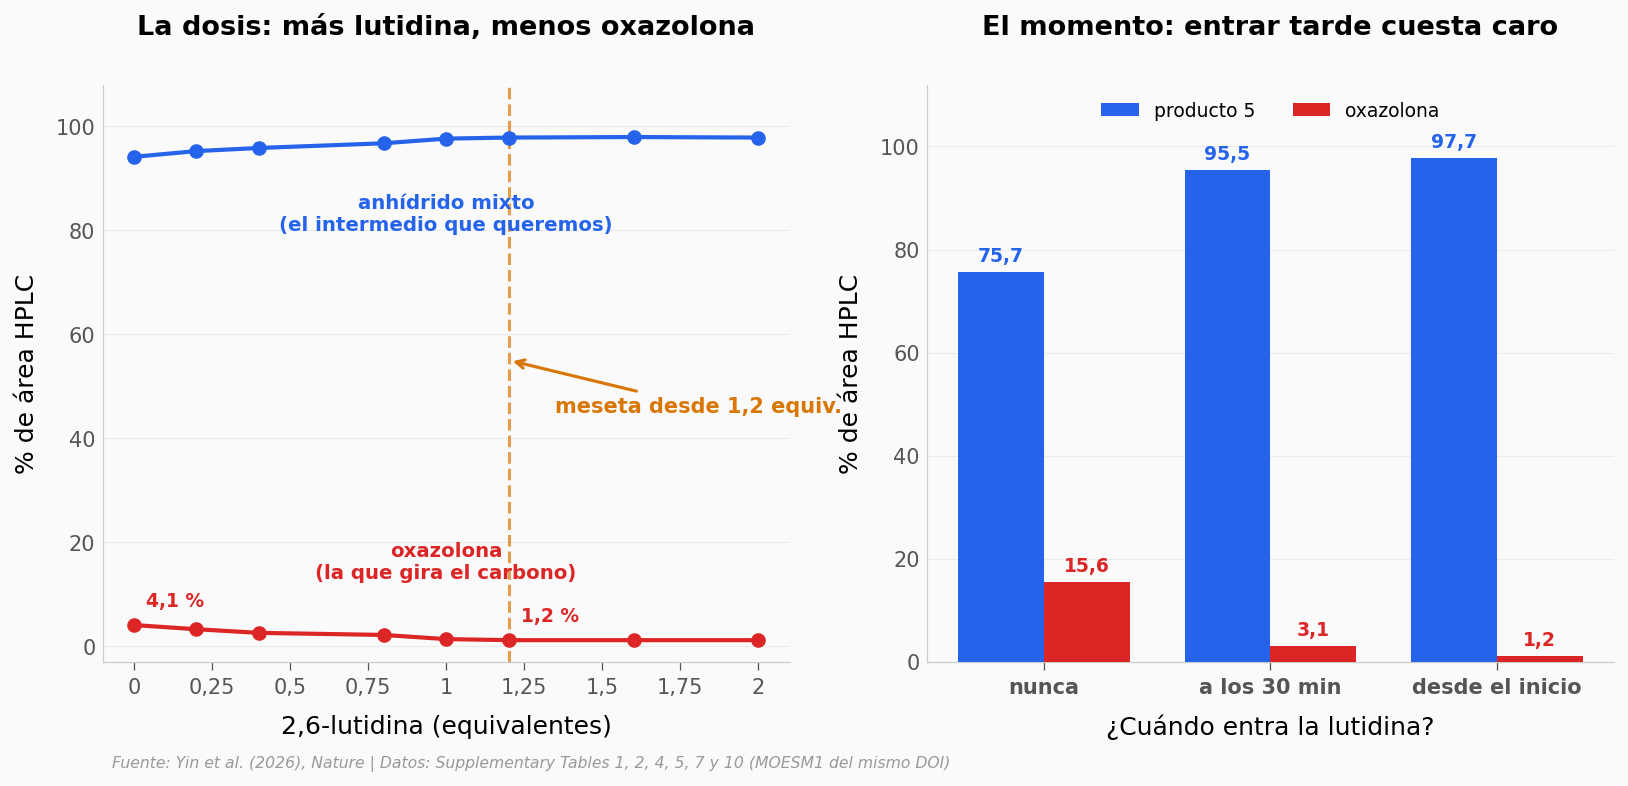

Dosis vs oxazolona: Spearman rho = −0,976 (n=8, p = 3,4×10^−5) — correlación de rangos, no varianza explicada
Oxazolona: 4,1 % sin lutidina -> 1,4 % con 1,0 equiv. -> meseta en 1,2 %
Máximo de anhídrido mixto en la serie: 97,9 %
Momento: sin lutidina producto 5 = 75,7 % y oxazolona 15,6 % | desde el inicio 97,7 % y 1,2 %


In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Panel izquierdo: dosis-respuesta (Suppl. Table 5, 5 h)
ax1.plot(ld.lutidina_equiv, ld.anhidrido_mixto_pct, 'o-', color=COLOR_DATOS, lw=2, ms=6, zorder=5)
ax1.plot(ld.lutidina_equiv, ld.oxazolona_pct, 'o-', color=COLOR_ALERTA, lw=2, ms=6, zorder=5)
ax1.text(1.0, 80, 'anhídrido mixto\n(el intermedio que queremos)',
         fontsize=9.5, color=COLOR_DATOS, fontweight='bold', ha='center')
ax1.text(1.0, 13, 'oxazolona\n(la que gira el carbono)',
         fontsize=9.5, color=COLOR_ALERTA, fontweight='bold', ha='center')
for i in (0, 5):
    ax1.text(ld.lutidina_equiv.iloc[i] + 0.04, ld.oxazolona_pct.iloc[i] + 3.5,
             es(f'{ld.oxazolona_pct.iloc[i]} %'), fontsize=9, color=COLOR_ALERTA, fontweight='bold')
MESETA = 1.2
ax1.axvline(x=MESETA, color=COLOR_REFERENCIA, lw=1.5, ls='--', alpha=0.7)
ax1.annotate(es(f'meseta desde {MESETA} equiv.'), xy=(MESETA, 55), xytext=(1.35, 45),
             fontsize=10, fontweight='bold', color=COLOR_REFERENCIA,
             arrowprops=dict(arrowstyle='->', color=COLOR_REFERENCIA, lw=1.5))
ax1.set_xlabel('2,6-lutidina (equivalentes)')
ax1.set_ylabel('% de área HPLC')
ax1.set_title('La dosis: más lutidina, menos oxazolona', fontsize=13, fontweight='bold')
ax1.set_ylim(-3, 108)
ax1.xaxis.set_major_formatter(COMA)
ax1.yaxis.set_major_formatter(COMA)

# Panel derecho: momento de adición (Suppl. Table 4, 20 h)
ETIQUETAS = {'sin 2,6-lutidina': 'nunca', '2,6-lutidina añadida a los 30 min': 'a los 30 min',
             '2,6-lutidina desde el inicio': 'desde el inicio'}
orden = ['sin 2,6-lutidina', '2,6-lutidina añadida a los 30 min', '2,6-lutidina desde el inicio']
lm_o = lm.set_index('condicion').loc[orden]
x = np.arange(len(orden))
ax2.bar(x - 0.19, lm_o.producto5_pct, width=0.38, color=COLOR_DATOS, label='producto 5', zorder=5)
ax2.bar(x + 0.19, lm_o.oxazolona_pct, width=0.38, color=COLOR_ALERTA, label='oxazolona', zorder=5)
for i, (p, o) in enumerate(zip(lm_o.producto5_pct, lm_o.oxazolona_pct)):
    ax2.text(i - 0.19, p + 2, es(f'{p}'), ha='center', fontsize=9, fontweight='bold', color=COLOR_DATOS)
    ax2.text(i + 0.19, o + 2, es(f'{o}'), ha='center', fontsize=9, fontweight='bold', color=COLOR_ALERTA)
ax2.set_xticks(x)
ax2.set_xticklabels([ETIQUETAS[c] for c in orden], fontsize=10, fontweight='bold')
ax2.set_xlabel('¿Cuándo entra la lutidina?')
ax2.set_ylabel('% de área HPLC')
ax2.set_ylim(0, 112)
ax2.set_title('El momento: entrar tarde cuesta caro', fontsize=13, fontweight='bold')
ax2.legend(fontsize=9, loc='upper center', framealpha=0.9, ncol=2)
ax2.yaxis.set_major_formatter(COMA)

fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/lutidina_dosis_momento.png', dpi=200, bbox_inches='tight')
plt.show()

rho = stats.spearmanr(ld.lutidina_equiv, ld.oxazolona_pct)
pr(f'Dosis vs oxazolona: Spearman rho = {rho.statistic:.3f} (n={len(ld)}, p = {rho.pvalue:.2g}) — correlación de rangos, no varianza explicada')
pr(f'Oxazolona: {ld.oxazolona_pct.iloc[0]} % sin lutidina -> {ld[ld.lutidina_equiv == 1.0].oxazolona_pct.iloc[0]} % con 1,0 equiv. -> meseta en {ld.oxazolona_pct.min()} %')
pr(f'Máximo de anhídrido mixto en la serie: {ld.anhidrido_mixto_pct.max()} %')
pr(f'Momento: sin lutidina producto 5 = {lm_o.producto5_pct.iloc[0]} % y oxazolona {lm_o.oxazolona_pct.iloc[0]} % | desde el inicio {lm_o.producto5_pct.iloc[2]} % y {lm_o.oxazolona_pct.iloc[2]} %')

## Lo que la lutidina compra es velocidad

La dosis-respuesta se mide a las 5 horas y el momento de adición a las 20. Pero si el método va a ser **continuo** —aminoácido tras aminoácido, sin aislar nada en medio— lo que importa es cuánto tarda cada paso en estar listo. Veamos la activación minuto a minuto, con cuatro recetas de base.

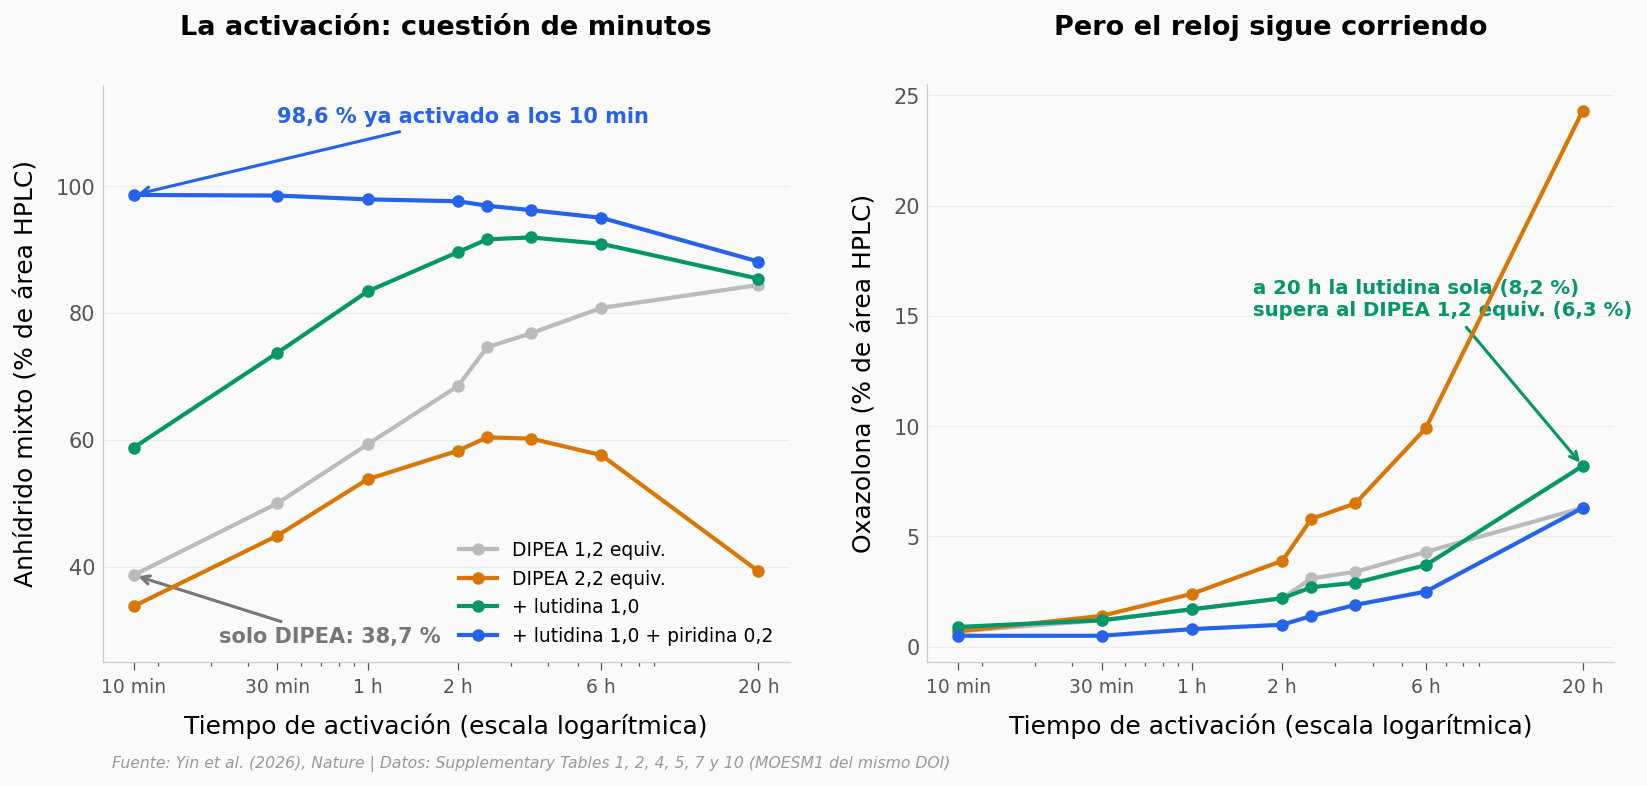

DIPEA 1,2 equiv.               anhídrido a 10 min =  38,7 % | máximo =  84,4 % | oxazolona a 20 h =   6,3 %
DIPEA 2,2 equiv.               anhídrido a 10 min =  33,8 % | máximo =  60,4 % | oxazolona a 20 h =  24,3 %
+ lutidina 1,0                 anhídrido a 10 min =  58,8 % | máximo =  91,9 % | oxazolona a 20 h =   8,2 %
+ lutidina 1,0 + piridina 0,2  anhídrido a 10 min =  98,6 % | máximo =  98,6 % | oxazolona a 20 h =   6,3 %


In [4]:
CONDICIONES = {'DIPEA 1,2 equiv.': (COLOR_GRIS, 'DIPEA 1,2 equiv.'),
               'DIPEA 2,2 equiv.': (COLOR_REFERENCIA, 'DIPEA 2,2 equiv.'),
               'DIPEA 1,2 + lutidina 1,0 equiv.': (COLOR_SEC, '+ lutidina 1,0'),
               'DIPEA 1,2 + lutidina 1,0 + piridina 0,2 equiv.': (COLOR_DATOS, '+ lutidina 1,0 + piridina 0,2')}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for cond, (color, etiqueta) in CONDICIONES.items():
    sub = ci[ci.condicion == cond].sort_values('tiempo_h')
    ax1.plot(sub.tiempo_h, sub.anhidrido_mixto_pct, 'o-', color=color, lw=2, ms=5, label=etiqueta, zorder=5)
    ax2.plot(sub.tiempo_h, sub.oxazolona_pct, 'o-', color=color, lw=2, ms=5, label=etiqueta, zorder=5)

d10 = ci[ci.tiempo_h < 0.2].set_index('condicion')
ax1.set_ylim(25, 116)
ax1.annotate(es(f'{d10.loc["DIPEA 1,2 + lutidina 1,0 + piridina 0,2 equiv.", "anhidrido_mixto_pct"]} % ya activado a los 10 min'),
             xy=(0.1667, 98.6), xytext=(0.5, 110), fontsize=10, fontweight='bold', color=COLOR_DATOS,
             arrowprops=dict(arrowstyle='->', color=COLOR_DATOS, lw=1.5))
ax1.annotate(es(f'solo DIPEA: {d10.loc["DIPEA 1,2 equiv.", "anhidrido_mixto_pct"]} %'),
             xy=(0.1667, 38.7), xytext=(0.32, 28), fontsize=10, fontweight='bold', color='#777777',
             arrowprops=dict(arrowstyle='->', color='#777777', lw=1.5))
for ax, col, titulo in [(ax1, 'anhidrido_mixto_pct', 'La activación: cuestión de minutos'),
                        (ax2, 'oxazolona_pct', 'Pero el reloj sigue corriendo')]:
    ax.set_xscale('log')
    ax.set_xticks([0.1667, 0.5, 1, 2, 6, 20])
    ax.set_xticklabels(['10 min', '30 min', '1 h', '2 h', '6 h', '20 h'], fontsize=9)
    ax.set_xlabel('Tiempo de activación (escala logarítmica)')
    ax.set_ylabel('% de área HPLC')
    ax.set_title(titulo, fontsize=13, fontweight='bold')
    ax.yaxis.set_major_formatter(COMA)
ax1.set_ylabel('Anhídrido mixto (% de área HPLC)')
ax2.set_ylabel('Oxazolona (% de área HPLC)')
ax1.legend(fontsize=9, loc='lower right', framealpha=0.9)
h20 = ci[ci.tiempo_h == 20].set_index('condicion')
ax2.annotate(es(f'a 20 h la lutidina sola ({h20.loc["DIPEA 1,2 + lutidina 1,0 equiv.", "oxazolona_pct"]} %)\nsupera al DIPEA 1,2 equiv. ({h20.loc["DIPEA 1,2 equiv.", "oxazolona_pct"]} %)'),
             xy=(20, 8.2), xytext=(1.6, 15), fontsize=9.5, fontweight='bold', color=COLOR_SEC,
             arrowprops=dict(arrowstyle='->', color=COLOR_SEC, lw=1.5))

fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/cinetica_activacion.png', dpi=200, bbox_inches='tight')
plt.show()

for cond, (_, etiqueta) in CONDICIONES.items():
    sub = ci[ci.condicion == cond].sort_values('tiempo_h')
    pr(f'{etiqueta:<30} anhídrido a 10 min = {sub.anhidrido_mixto_pct.iloc[0]:>5} % | máximo = {sub.anhidrido_mixto_pct.max():>5} % | oxazolona a 20 h = {sub.oxazolona_pct.iloc[-1]:>5} %')

## El examen final: echarle agua

Un anhídrido mixto y el agua no son amigos. Y cualquier método que vaya a salir de la vitrina de cristal —a un reactor, a una planta— se va a encontrar con humedad en los disolventes. El material suplementario trae el ensayo que más se parece a una prueba de resistencia: hasta 15 equivalentes de agua añadidos a propósito, con lutidina y sin ella.

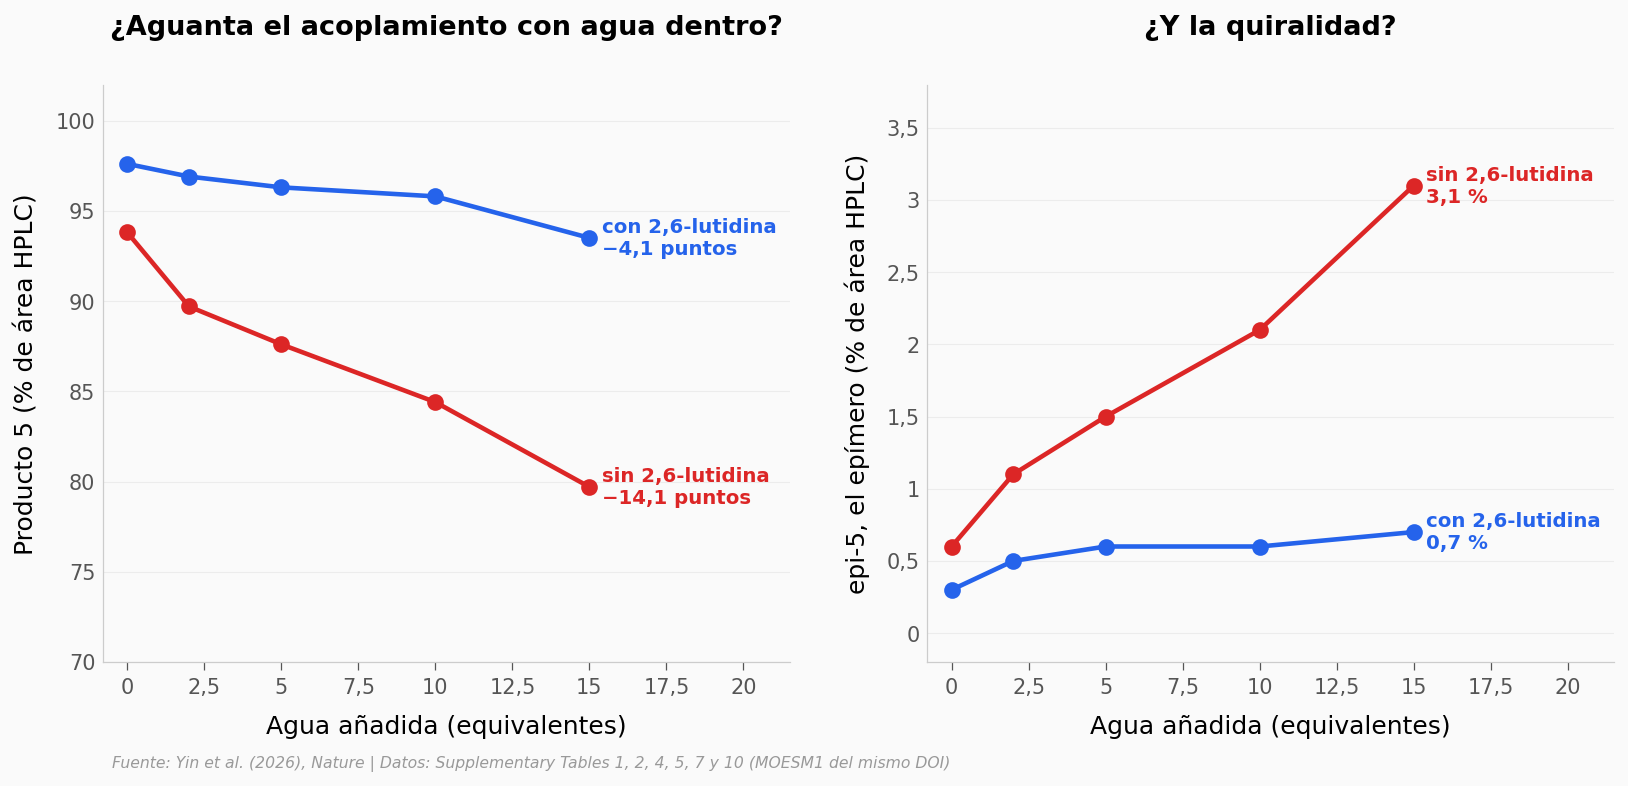

con 2,6-lutidina: producto 5 97,6 % -> 93,5 % | epi-5 0,3 % -> 0,7 % | oxazolona 1,0 % -> 2,2 %
sin 2,6-lutidina: producto 5 93,8 % -> 79,7 % | epi-5 0,6 % -> 3,1 % | oxazolona 3,5 % -> 12,9 %
Ventaja de la lutidina por nivel de agua (0 a 15,0 equiv.): +3,8 / +7,2 / +8,7 / +11,4 / +13,8 puntos | d pareado = 2,33 (n=5 niveles, un dato por nivel)


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
GRUPOS_AGUA = {'con 2,6-lutidina': (COLOR_DATOS, 'con 2,6-lutidina'),
               'sin 2,6-lutidina': (COLOR_ALERTA, 'sin 2,6-lutidina')}
for cond, (color, etiqueta) in GRUPOS_AGUA.items():
    sub = ag[ag.condicion == cond].sort_values('agua_equiv')
    ax1.plot(sub.agua_equiv, sub.s2_producto5_pct, 'o-', color=color, lw=2.2, ms=7, zorder=5)
    ax2.plot(sub.agua_equiv, sub.s2_epi5_pct, 'o-', color=color, lw=2.2, ms=7, zorder=5)
    caida = sub.s2_producto5_pct.iloc[-1] - sub.s2_producto5_pct.iloc[0]
    ax1.text(AGUA_MAX + 0.4, sub.s2_producto5_pct.iloc[-1], es(f'{etiqueta}\n{caida:+.1f} puntos'),
             fontsize=9.5, color=color, fontweight='bold', va='center')
    ax2.text(AGUA_MAX + 0.4, sub.s2_epi5_pct.iloc[-1], es(f'{etiqueta}\n{sub.s2_epi5_pct.iloc[-1]} %'),
             fontsize=9.5, color=color, fontweight='bold', va='center')

for ax, titulo, ylab in [(ax1, '¿Aguanta el acoplamiento con agua dentro?', 'Producto 5 (% de área HPLC)'),
                         (ax2, '¿Y la quiralidad?', 'epi-5, el epímero (% de área HPLC)')]:
    ax.set_xlabel('Agua añadida (equivalentes)')
    ax.set_ylabel(ylab)
    ax.set_title(titulo, fontsize=13, fontweight='bold')
    ax.set_xlim(-0.8, AGUA_MAX + 6.5)
    ax.xaxis.set_major_formatter(COMA)
    ax.yaxis.set_major_formatter(COMA)
ax1.set_ylim(70, 102)
ax2.set_ylim(-0.2, 3.8)

fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/agua_tolerancia.png', dpi=200, bbox_inches='tight')
plt.show()

c_lut = ag[ag.condicion == 'con 2,6-lutidina'].sort_values('agua_equiv').s2_producto5_pct.values
s_lut = ag[ag.condicion == 'sin 2,6-lutidina'].sort_values('agua_equiv').s2_producto5_pct.values
vent = c_lut - s_lut
txt = ' / '.join(f'{v:+.1f}' for v in vent)
for cond in GRUPOS_AGUA:
    sub = ag[ag.condicion == cond].sort_values('agua_equiv')
    pr(f'{cond}: producto 5 {sub.s2_producto5_pct.iloc[0]} % -> {sub.s2_producto5_pct.iloc[-1]} % | epi-5 {sub.s2_epi5_pct.iloc[0]} % -> {sub.s2_epi5_pct.iloc[-1]} % | oxazolona {sub.s2_oxazolona_pct.iloc[0]} % -> {sub.s2_oxazolona_pct.iloc[-1]} %')
pr(f'Ventaja de la lutidina por nivel de agua (0 a {AGUA_MAX} equiv.): {txt} puntos | d pareado = {vent.mean() / vent.std(ddof=1):.2f} (n=5 niveles, un dato por nivel)')

## ¿Qué tan raro es un aditivo que ayude?

Mirar la lutidina de cerca deja la impresión de que basta con echar una base y listo. El cribado completo dice otra cosa.

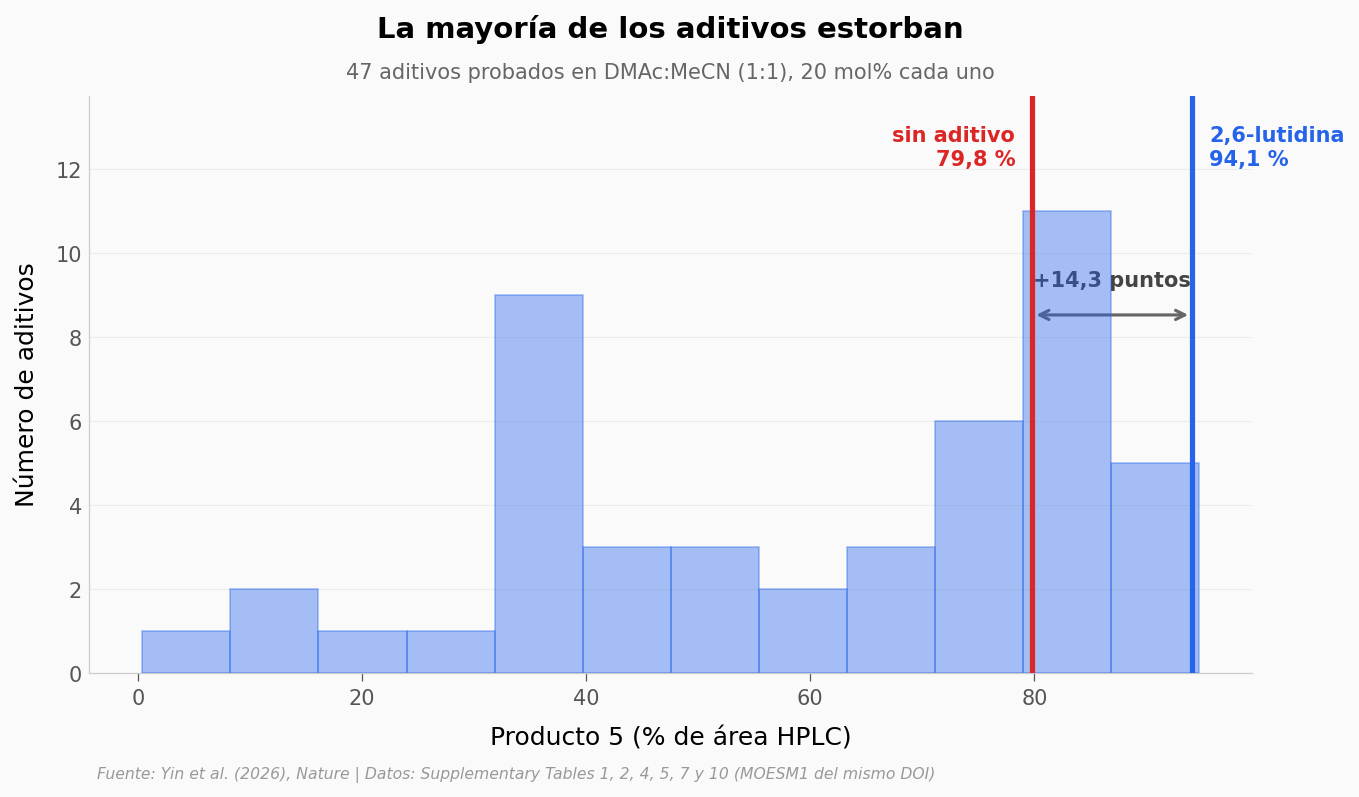

Superan al control: 13 de 47 (28 %) | mediana de los 47: 66,8 %
Percentil de la 2,6-lutidina entre los 47 aditivos: 96
Media geométrica por acoplamiento: 95,6 % desde el 73,0 % de ensayo y 95,2 % desde el 71 % aislado — las dos concuerdan con el ≥95 % del abstract


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
n, bins, patches = ax.hist(adds.producto5_pct, bins=12, color=COLOR_DATOS, alpha=0.4,
                           edgecolor=COLOR_DATOS, linewidth=0.8, zorder=4)
y_max = n.max() * 1.25
ax.set_ylim(0, y_max)
ax.axvline(x=ctrl.producto5_pct, color=COLOR_ALERTA, lw=2.5, zorder=6)
ax.axvline(x=lut.producto5_pct, color=COLOR_DATOS, lw=2.5, zorder=6)
ax.annotate('', xy=(lut.producto5_pct, y_max * 0.62), xytext=(ctrl.producto5_pct, y_max * 0.62),
            arrowprops=dict(arrowstyle='<->', color='#666666', lw=1.5))
ax.text((ctrl.producto5_pct + lut.producto5_pct) / 2, y_max * 0.67,
        es(f'{lut.producto5_pct - ctrl.producto5_pct:+.1f} puntos'),
        ha='center', fontsize=10, fontweight='bold', color='#444444')
ax.text(ctrl.producto5_pct - 1.5, y_max * 0.88, es(f'sin aditivo\n{ctrl.producto5_pct} %'),
        ha='right', fontsize=10, fontweight='bold', color=COLOR_ALERTA)
ax.text(lut.producto5_pct + 1.5, y_max * 0.88, es(f'2,6-lutidina\n{lut.producto5_pct} %'),
        ha='left', fontsize=10, fontweight='bold', color=COLOR_DATOS)
ax.set_xlabel('Producto 5 (% de área HPLC)')
ax.set_ylabel('Número de aditivos')
ax.set_title('La mayoría de los aditivos estorban', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, es(f'{len(adds)} aditivos probados en {BLOQUE}, 20 mol% cada uno'),
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
ax.xaxis.set_major_formatter(COMA)
ax.yaxis.set_major_formatter(COMA)
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/histograma_aditivos.png', dpi=200, bbox_inches='tight')
plt.show()

mejoran = adds[adds.producto5_pct > ctrl.producto5_pct]
pr(f'Superan al control: {len(mejoran)} de {len(adds)} ({100 * len(mejoran) / len(adds):.0f} %) | mediana de los 47: {adds.producto5_pct.median()} %')
pr(f'Percentil de la 2,6-lutidina entre los 47 aditivos: {100 * (adds.producto5_pct < lut.producto5_pct).mean():.0f}')
# Cross-check con el titular del abstract: 73,0 % de rendimiento de ensayo en 7 acoplamientos
# (unidad distinta de los % de área HPLC de arriba: ese 73 % es rendimiento)
pr(f'Media geométrica por acoplamiento: {100 * 0.730 ** (1 / 7):.1f} % desde el 73,0 % de ensayo y {100 * 0.71 ** (1 / 7):.1f} % desde el 71 % aislado — las dos concuerdan con el ≥95 % del abstract')

### Lo que los datos soportan

| Afirmación | ¿Soportada? | Detalle |
|------------|-------------|---------|
| Sin aditivo, el acoplamiento deja 79,8 % de producto 5 y 14,3 % de oxazolona total | ✅ | Control del bloque DMAc:MeCN (1:1) de la Suppl. Table 2, a las 16 h. Unidad: % de área HPLC a 210 nm |
| La 2,6-lutidina sube el producto a 94,1 % y baja la oxazolona a 4,3 % | ✅ | +14,3 puntos de producto y oxazolona 3,33 veces menor; el epímero epi-5 cae de 2,2 % a 0,6 % |
| Las piridinas sustituidas rinden más producto que las sales metálicas | ✅ | Mediana 91,8 % (n=5, IQR 91,3–94,1) frente a 61,6 % (n=35, IQR 34,6–78,7); Mann-Whitney p = 2,1×10⁻⁵, Cohen's d = 1,53. Con dos avisos: n=5 es poco, y agrupar por familia química es nuestra decisión, no del paper |
| La 2,6-lutidina es el aditivo que más producto da | ❌ | La 2,4,6-colidina da más (94,7 % frente a 94,1 %), pero con casi el doble de oxazolona total (8,1 % frente a 4,3 %). El criterio del método es suprimir oxazolona y epímero, no maximizar producto |
| Más lutidina, menos oxazolona, con meseta a partir de 1,2 equivalentes | ✅ | Spearman ρ = −0,976 (n=8, p = 3,4×10⁻⁵) en la Suppl. Table 5; la oxazolona baja de 4,1 % a 1,4 % con 1,0 equiv. y se queda en 1,2 %. ρ es correlación de rangos: no se traduce a varianza explicada |
| Añadir la lutidina desde el inicio importa | ✅ | Suppl. Table 4, 20 h: nunca → 75,7 % de producto y 15,6 % de oxazolona; a los 30 min → 95,5 % y 3,1 %; desde el inicio → 97,7 % y 1,2 % |
| Con lutidina y piridina, la activación está lista en 10 minutos | ✅ | 98,6 % de anhídrido mixto a los 10 min, frente a 38,7 % con solo DIPEA 1,2 equiv. (Suppl. Table 7) |
| La lutidina protege de la oxazolona en todo momento | ❌ | A las 20 h la lutidina sola deja 8,2 % de oxazolona, por encima del 6,3 % del DIPEA 1,2 equiv. Y el anhídrido mixto envejece en las dos recetas con lutidina: de 98,6 % a 88,1 % con lutidina más piridina, y de un máximo de 91,9 % a 85,4 % con lutidina sola. Lo que los datos soportan es una ventaja de velocidad, no un blindaje permanente |
| El método tolera hasta 15 equivalentes de agua | ✅ | Con lutidina, el producto baja −4,1 puntos (97,6 % → 93,5 %) y el epímero queda en 0,7 %; sin ella la caída es −14,1 puntos (93,8 % → 79,7 %) y el epímero sube a 3,1 %. La ventaja de la lutidina crece con el agua, de +3,8 a +13,8 puntos (d pareado = 2,33 sobre los 5 niveles; con un solo dato por nivel, el Wilcoxon no puede bajar de p = 0,0625) |
| ≥95 % de rendimiento medio por acoplamiento y ≤1,0 % de epimerización | ✅ | Cifras del abstract, no de estas tablas. Cross-check nuestro: el 73,0 % de rendimiento de ensayo en 7 acoplamientos da una media geométrica de 95,6 % por acoplamiento |
| El disolvente cambia el resultado del cribado | ⚠️ | Comparación pareada de las mismas 48 entradas (47 aditivos y el control): mediana 78,4 % en DMAc frente a 67,0 % en DMAc:MeCN, pero efecto pequeño (d pareado = 0,21; Wilcoxon p = 0,037). Dejando fuera el control, el efecto es el mismo (d pareado = 0,20) y el p sube a 0,052: la comparación no aguanta un umbral. El paper no la plantea — contexto, no hallazgo |
| El método podría transformar la fabricación de péptidos | ⚠️ | El abstract dice «tiene el potencial de transformar», y los ~10 veces menos aislamientos y hasta ~100 veces menos residuos son cifras suyas, no de estos datos. Es un potencial medido en un modelo de reacción y cuatro péptidos, no una planta funcionando |

> **Limitaciones:**
> - Todas las cifras de los seis CSV son **% de área por HPLC a 210 nm** (pureza relativa en la mezcla de reacción), no rendimiento aislado. Los 73,0 % y 71 % de la síntesis de los 7 acoplamientos sí son rendimientos: no se comparan con los demás números.
> - Todo el cribado se hizo sobre **un solo modelo de reacción** (un dipéptido más un aminoácido). Los porcentajes no se extrapolan a la semaglutida, la tirzepatida ni la degarelix: para esos, el paper reporta cifras propias.
> - Las familias químicas (piridinas, sales metálicas, otros) son **una clasificación nuestra** para poder comparar distribuciones; el paper lista los aditivos sin agruparlos.
> - Las entradas 47 y 48 (DMAP y NMI) calculan su oxazolona con otra fórmula, que incluye el epímero del material de partida. Quedan fuera del gráfico principal y de cualquier comparación de oxazolona.
> - El material suplementario no reporta réplicas de estas tablas: hay **un dato por condición**, así que no hay dispersión experimental que medir ni intervalos que calcular.
> - El cuerpo del paper está tras un muro de pago. Lo que exploramos son sus tablas suplementarias y su resumen; los detalles de los métodos no se pueden verificar aquí.

## Ahora tú

1. **¿Cambia el podio si el criterio es la oxazolona y no el producto?** Ordena el cribado por `oxazolona_total_pct` en vez de por producto, dejando fuera las entradas 47 y 48: `adds[~adds.entry.isin([47, 48])].nsmallest(8, 'oxazolona_total_pct')`.
2. **¿Y si el disolvente fuera lo que manda?** Las mismas 48 entradas están medidas en DMAc y en DMAc:MeCN. Cruza los dos bloques con `ad.pivot_table(index='entry', columns='solvente', values='producto5_pct')` y mira cuántos aditivos cambian de lado. Ojo con el tamaño del efecto antes de titular.
3. **¿Qué hacían los reactivos de siempre?** Antes de los aditivos, el equipo probó ocho formas de activar el ácido. La celda de abajo las compara: fíjate en el epi-5 del HATU, el reactivo estándar de la síntesis en fase sólida.

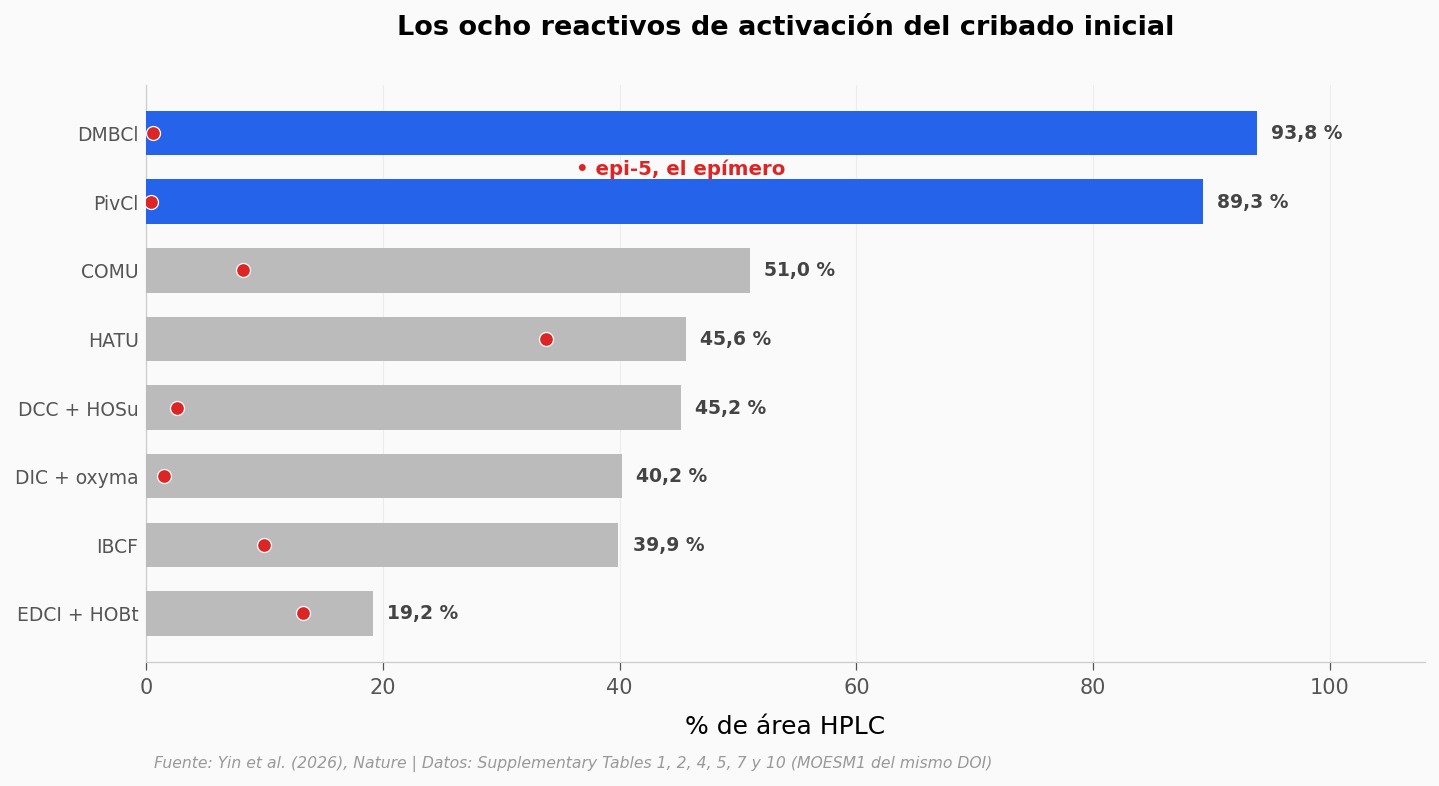

Disolvente, 48 entradas pareadas: mediana 78,45 % en DMAc vs 67,0 % en DMAc:MeCN (1:1) | d pareado = 0,21 | Wilcoxon p = 0,037
Sin el control, los 47 aditivos: d pareado = 0,20 | Wilcoxon p = 0,052 — el umbral de 0,05 queda en el aire
Mejor reactivo del cribado: DMBCl con 93,8 % de producto y epi-5 0,6 %
HATU, el estándar de la síntesis en fase sólida: 45,6 % de producto y epi-5 33,8 % — un tercio largo de la mezcla girado al revés


In [7]:
# --- EXPERIMENTA AQUÍ ---
# Suppl. Table 1: los 8 reactivos de activación probados antes de llegar al DMBCl, a 16 h.
CORTO = {1: 'HATU', 2: 'EDCI + HOBt', 3: 'COMU', 4: 'DIC + oxyma',
         5: 'DCC + HOSu', 6: 'IBCF', 7: 'PivCl', 8: 'DMBCl'}
rg_o = rg.sort_values('producto5_pct')
NOMBRE_CORTO = [CORTO[e] for e in rg_o.entry]

fig, ax = plt.subplots(figsize=(11, 5))
colores = [COLOR_DATOS if v >= 85 else COLOR_GRIS for v in rg_o.producto5_pct]
ax.barh(np.arange(len(rg_o)), rg_o.producto5_pct, color=colores, zorder=5, height=0.65)
ax.scatter(rg_o.epi5_pct, np.arange(len(rg_o)), color=COLOR_ALERTA, s=45, zorder=6,
           edgecolors='white', linewidths=0.6)
for i, (p, e) in enumerate(zip(rg_o.producto5_pct, rg_o.epi5_pct)):
    ax.text(p + 1.2, i, es(f'{p} %'), va='center', fontsize=9, fontweight='bold', color='#444444')
ax.text(rg_o.epi5_pct.max() + 2.5, len(rg_o) - 1.6, es('• epi-5, el epímero'),
        fontsize=9.5, color=COLOR_ALERTA, fontweight='bold')
ax.set_yticks(np.arange(len(rg_o)))
ax.set_yticklabels(NOMBRE_CORTO, fontsize=9)
ax.set_xlabel('% de área HPLC')
ax.set_title('Los ocho reactivos de activación del cribado inicial', fontsize=13, fontweight='bold')
ax.set_xlim(0, 108)
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)
ax.xaxis.set_major_formatter(COMA)
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/reagentes_clasicos.png', dpi=200, bbox_inches='tight')
plt.show()

# ¿Manda el disolvente? Comparación pareada de las 48 entradas medidas en los dos bloques
piv = ad.pivot_table(index='entry', columns='solvente', values='producto5_pct').dropna()
dif = piv['DMAc'] - piv[BLOQUE]
w48 = stats.wilcoxon(piv['DMAc'], piv[BLOQUE])
piv47 = piv.drop(index=int(ctrl.entry))
dif47 = piv47['DMAc'] - piv47[BLOQUE]
w47 = stats.wilcoxon(piv47['DMAc'], piv47[BLOQUE])
pr(f'Disolvente, {len(piv)} entradas pareadas: mediana {piv["DMAc"].median():.2f} % en DMAc vs {piv[BLOQUE].median():.1f} % en {BLOQUE} | d pareado = {dif.mean() / dif.std(ddof=1):.2f} | Wilcoxon p = {w48.pvalue:.3f}')
pr(f'Sin el control, los {len(piv47)} aditivos: d pareado = {dif47.mean() / dif47.std(ddof=1):.2f} | Wilcoxon p = {w47.pvalue:.3f} — el umbral de 0,05 queda en el aire')

hatu = rg[rg.reagente.str.startswith('HATU')].iloc[0]
mejor = rg.loc[rg.producto5_pct.idxmax()]
pr(f'Mejor reactivo del cribado: {CORTO[mejor.entry]} con {mejor.producto5_pct} % de producto y epi-5 {mejor.epi5_pct} %')
pr(f'HATU, el estándar de la síntesis en fase sólida: {hatu.producto5_pct} % de producto y epi-5 {hatu.epi5_pct} % — un tercio largo de la mezcla girado al revés')
# Prueba cambiando la columna a 'oxazolona_pct' o a 'sobreadicion6_pct' para ver qué falla en cada reactivo.

## Créditos

**Paper:** Yin et al. (2026). *Continuous N-to-C Peptide Synthesis*. Nature. DOI: [10.1038/s41586-026-11448-w](https://doi.org/10.1038/s41586-026-11448-w) · Acceso restringido (solo resumen y material suplementario).

**Datos:** Supplementary Tables 1, 2, 4, 5, 7 y 10 del material suplementario del mismo DOI (MOESM1), transcritas por nosotros a CSV. Todas las cifras son % de área por HPLC a 210 nm.

**Repositorio:** [Ciencia-a-Mordiscos/lab](https://github.com/Ciencia-a-Mordiscos/lab)

## Fuentes

**Paper**: [Continuous N-to-C Peptide Synthesis](https://doi.org/10.1038/s41586-026-11448-w)  
*Nature, 2026-11-23*

**Supplementary Material**: [Supplementary Information for Continuous N-to-C Peptide Synthesis (MOESM1): Materials and Methods, Supplementary Tables 1-10 y datos espectrales de RMN](https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-026-11448-w/MediaObjects/41586_2026_11448_MOESM1_ESM.pdf)  
*Nature, 2026-11-23*

*27 afirmaciones del notebook verificadas contra estas fuentes*